In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6,3)

In [2]:
def plot_data(df, x, y, title, x_label, y_label):
    fig, ax = plt.subplots()
    for key, grp in df.groupby(['optimizer']):
        ax = grp.plot(ax=ax, kind='line', x=x, y=y, label=key[0])
    ax.set_title(title, fontdict={'fontweight':'bold'})
    ax.set_xlabel(xlabel=x_label)
    ax.xaxis.get_label().set_fontstyle('italic')
    ax.yaxis.get_label().set_fontstyle('italic')
    ax.set_ylabel(ylabel=y_label)
    ax.grid(visible=True)
    plt.legend(loc='best')    
    plt.show()


In [3]:
df = pd.read_csv('classical_results.csv')
df['training_time'] = df['training_time'].divide(3600)
df = df.round(4)

In [4]:
df.sort_values(['r2'], ascending=False)

,n_features,n_targets,n_samples,test_size,optimizer,iterations,training_time,prediction_time,r2,mae,mse,rmse
55,3,2,500,30,lbfgs,100000,0.0,0.000,0.9812,0.0262,0.0011,0.0328
53,3,2,500,30,lbfgs,1000,0.0,0.000,0.9808,0.0270,0.0011,0.0333
54,3,2,500,30,lbfgs,10000,0.0,0.000,0.9800,0.0268,0.0012,0.0336
52,3,2,500,30,lbfgs,100,0.0,0.000,0.9787,0.0277,0.0013,0.0352
90,3,2,1000,30,lbfgs,10000,0.0,0.000,0.9638,0.0397,0.0024,0.0479
...,...,...,...,...,...,...,...,...,...,...,...,...
58,3,2,500,30,sgd,10000,0.0,0.000,0.0124,0.2058,0.0613,0.2431
59,3,2,500,30,sgd,100000,0.0,0.000,-0.0061,0.2056,0.0608,0.2467
2,3,2,100,20,adam,10000,0.0,0.001,-0.0278,0.2206,0.0664,0.2571
11,3,2,100,20,sgd,100000,0.0,0.001,-0.1310,0.2157,0.0736,0.2713


In [5]:
"""
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
"""
pd.set_option('display.max_rows', None)
df[(df['n_samples']==100)].to_html('classical_100_samples.html', index=False)
df[(df['n_samples']==500)].to_html('classical_500_samples.html', index=False)
df[(df['n_samples']==1000)].to_html('classical_1000_samples.html', index=False)

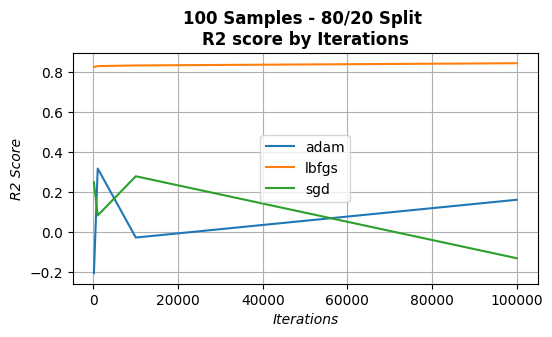

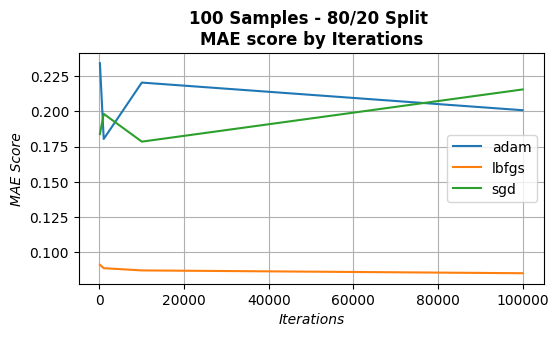

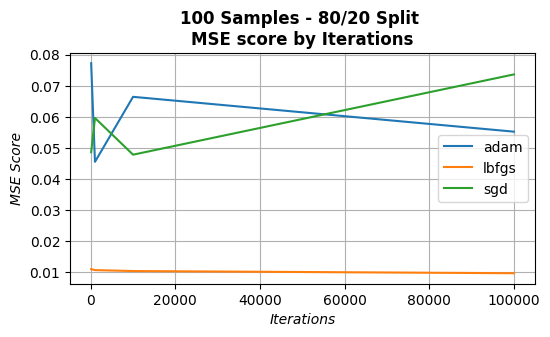

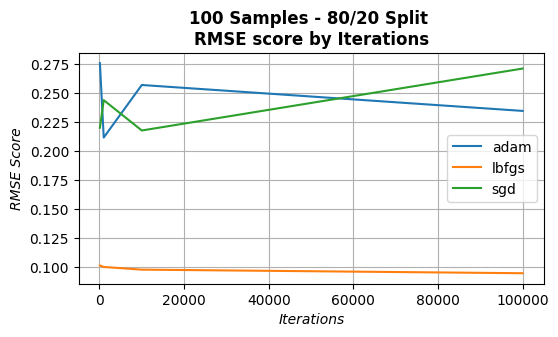

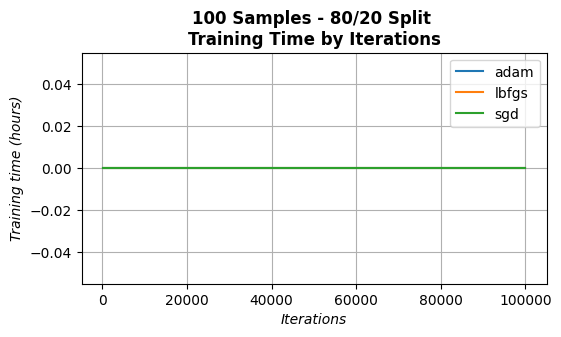

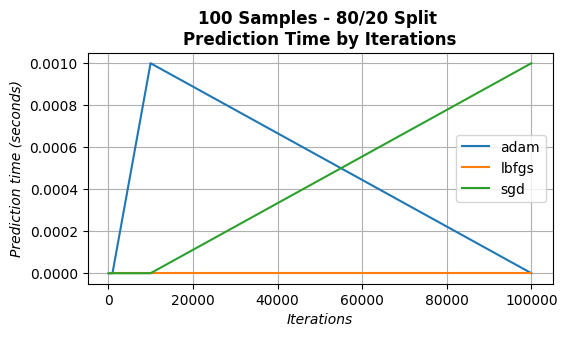

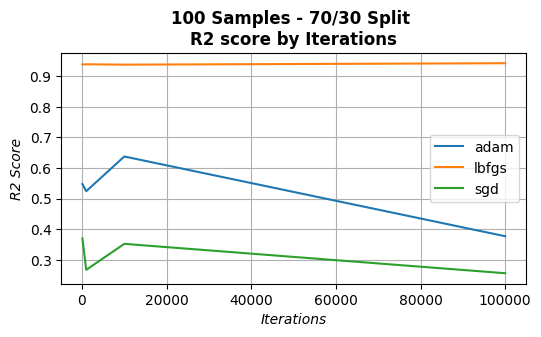

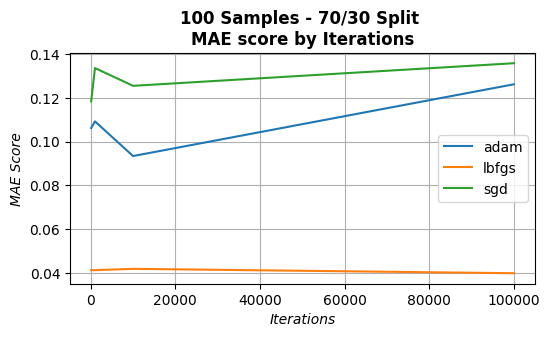

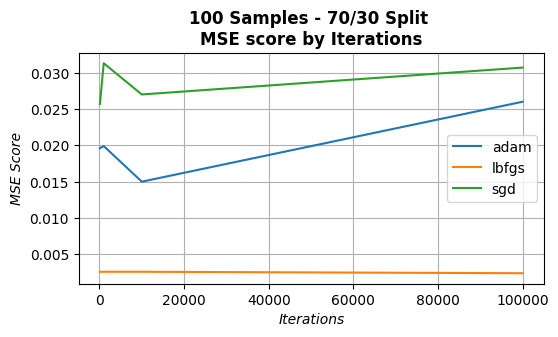

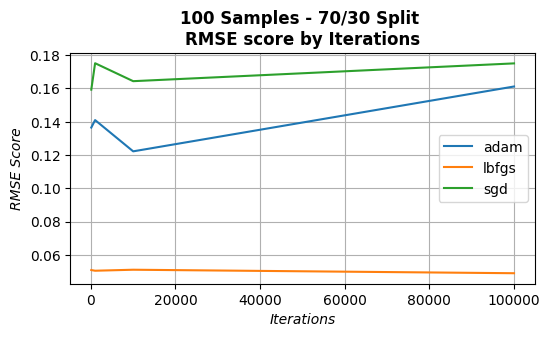

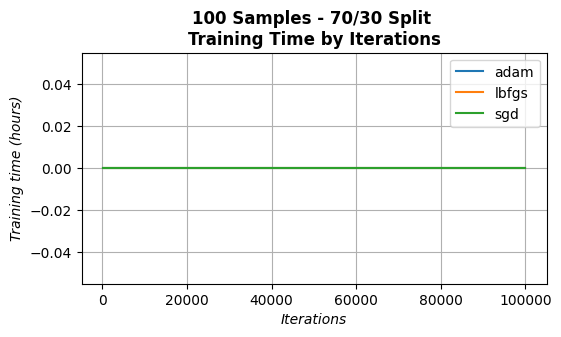

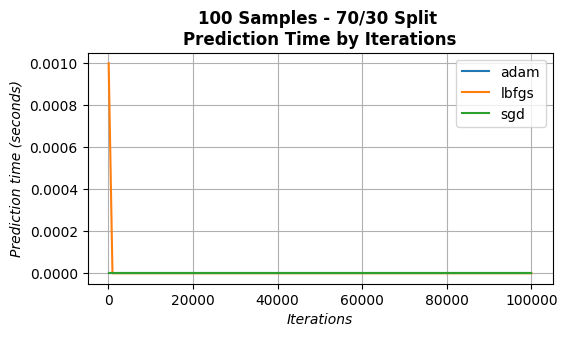

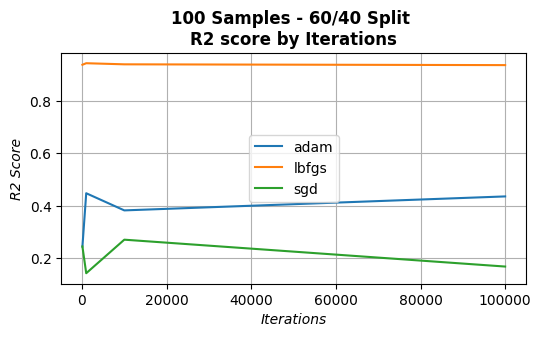

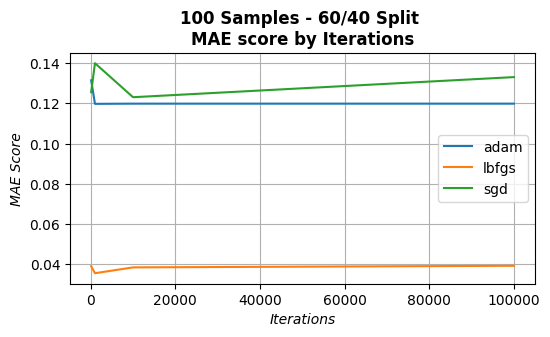

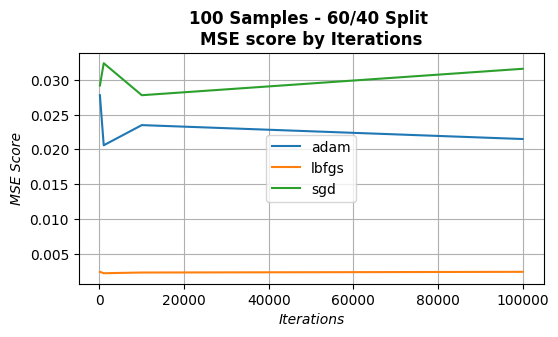

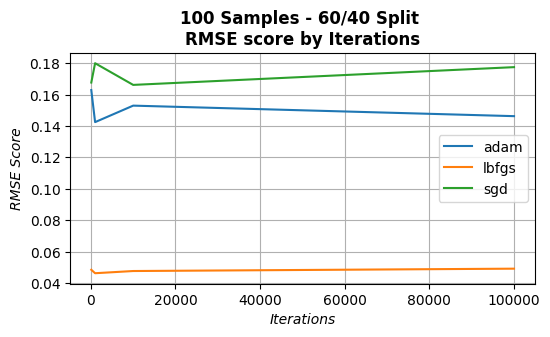

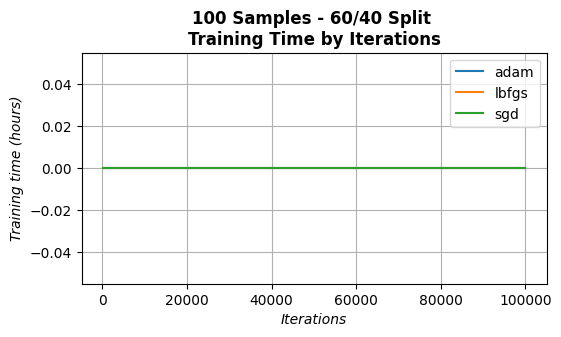

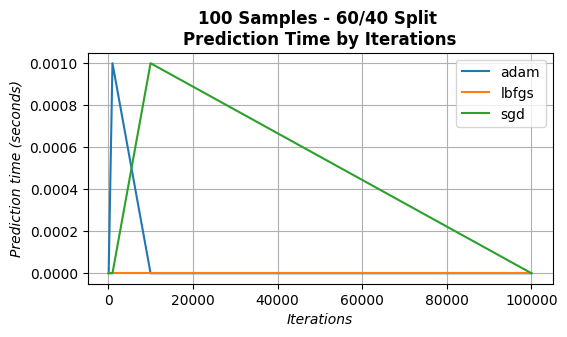

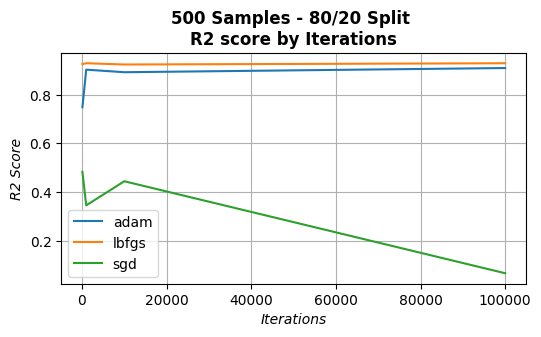

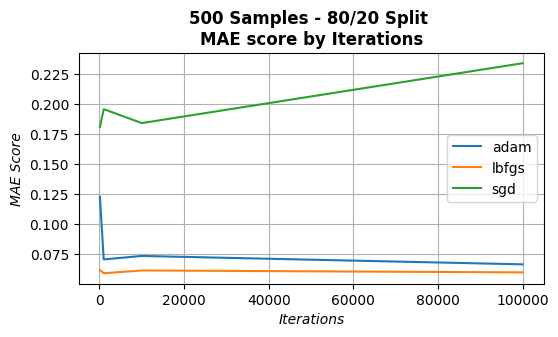

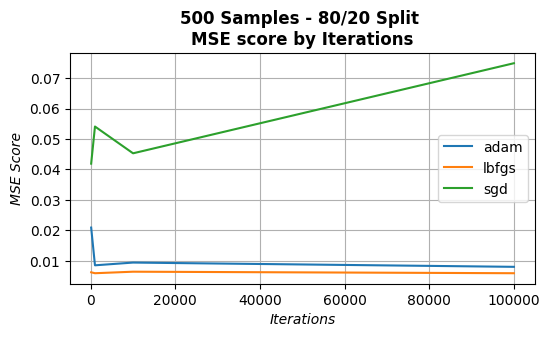

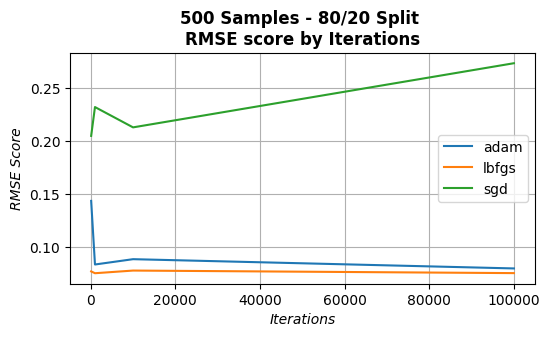

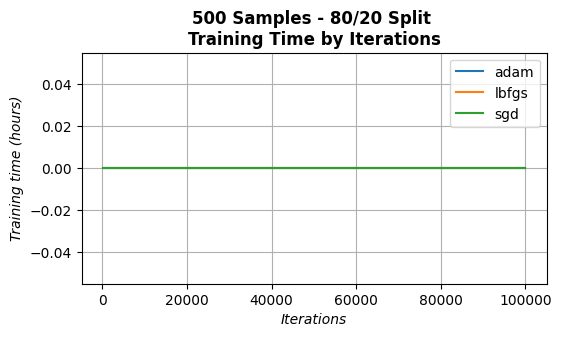

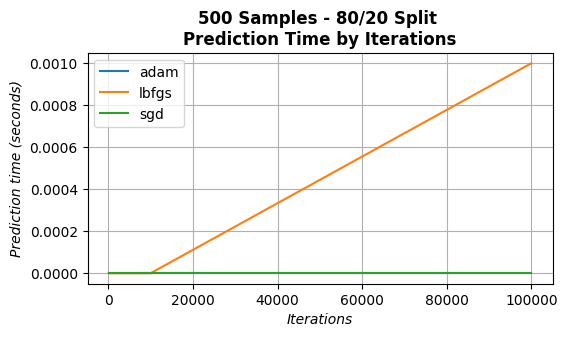

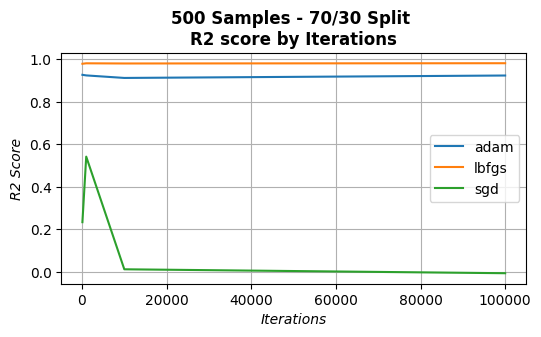

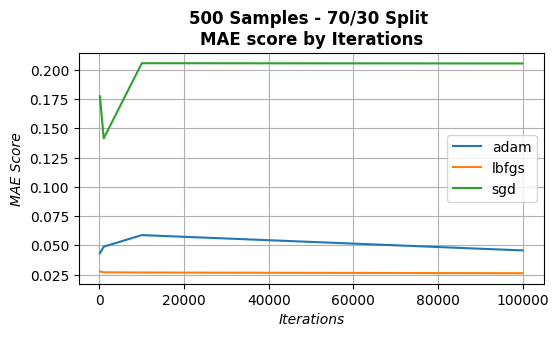

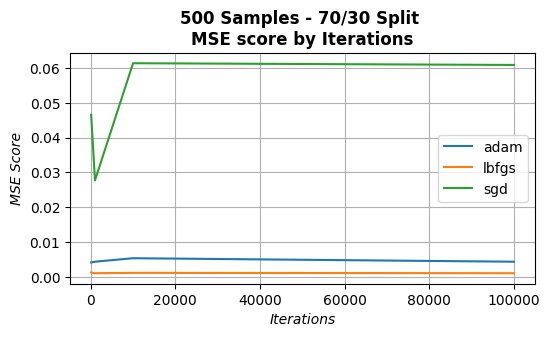

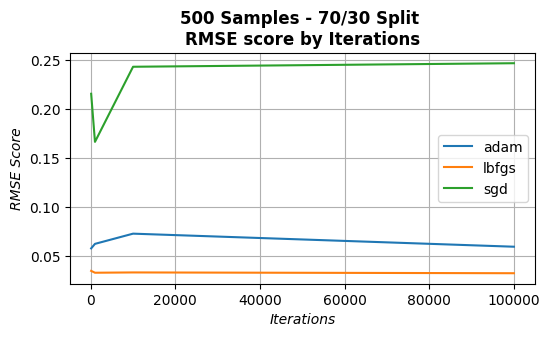

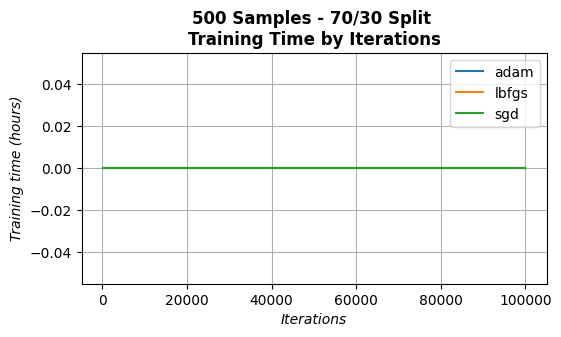

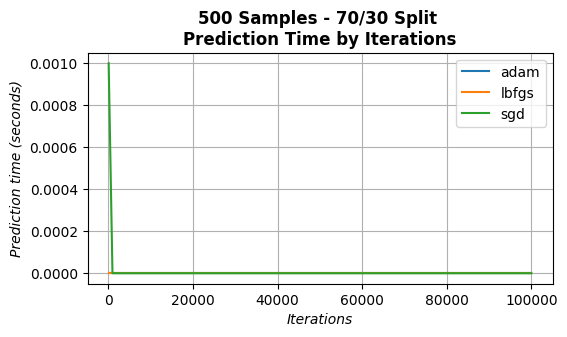

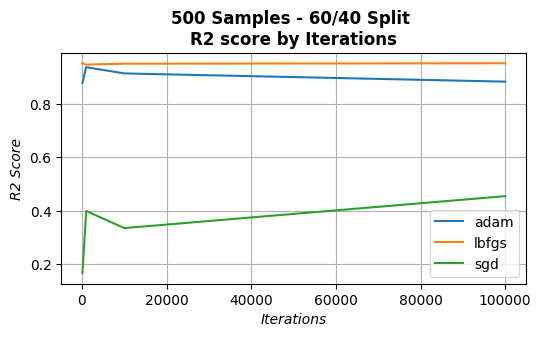

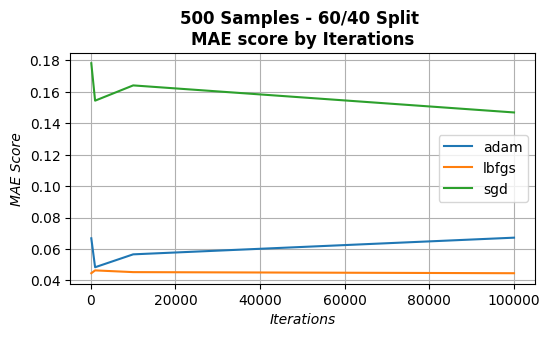

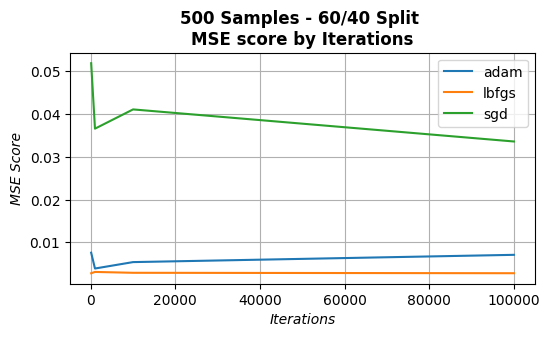

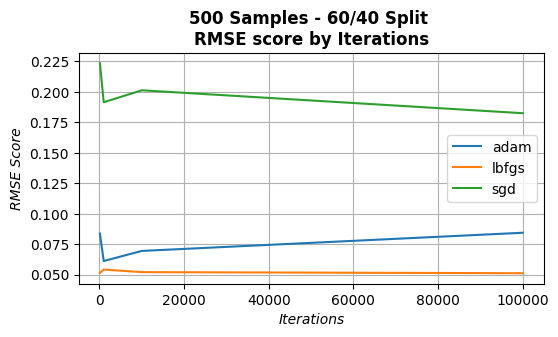

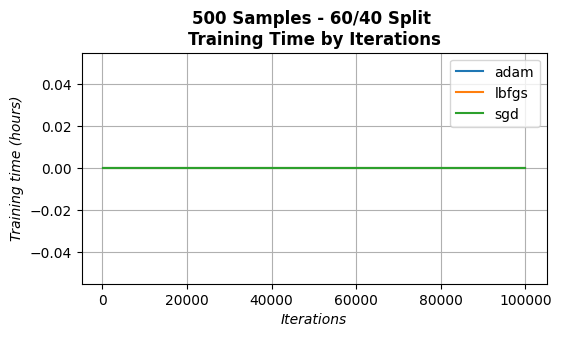

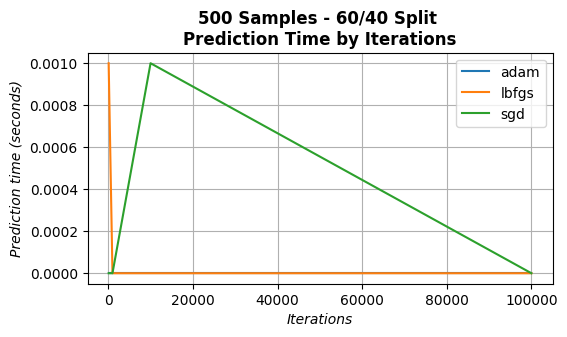

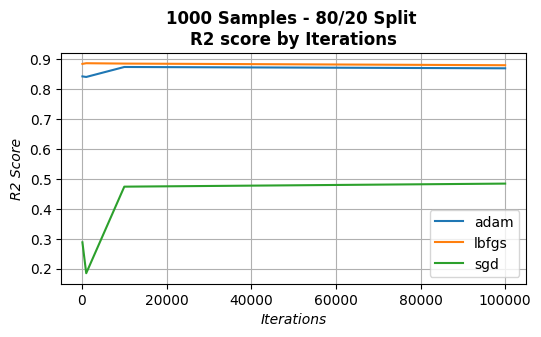

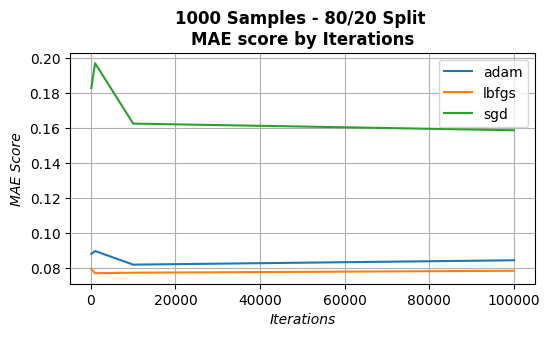

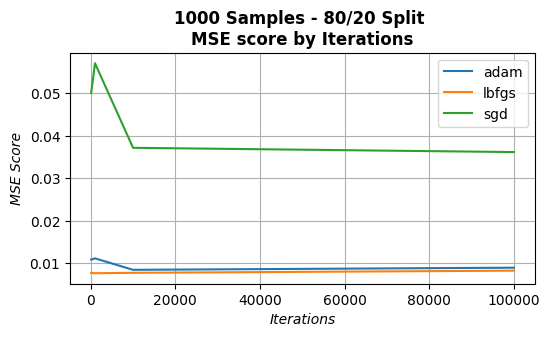

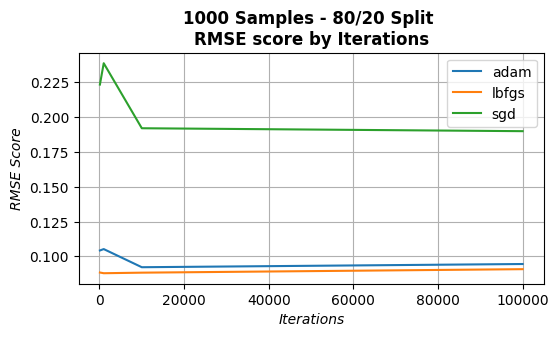

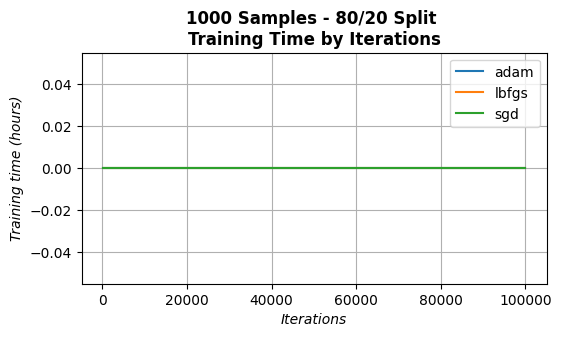

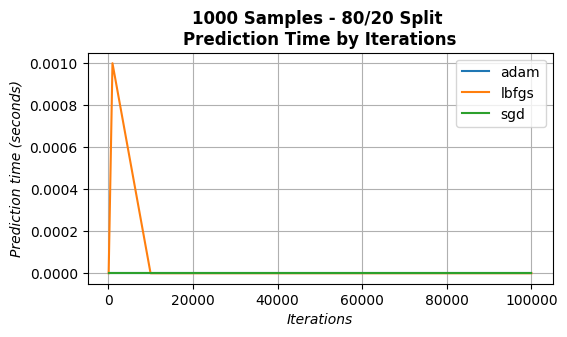

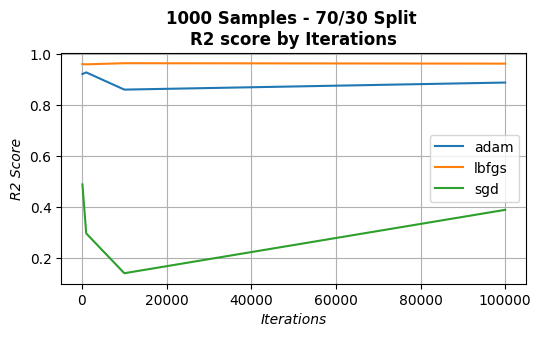

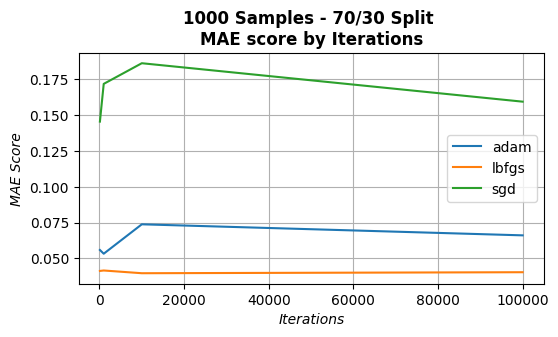

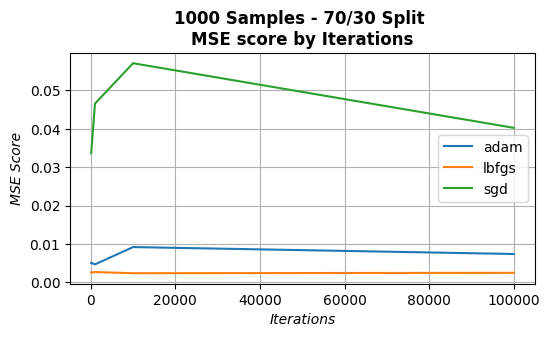

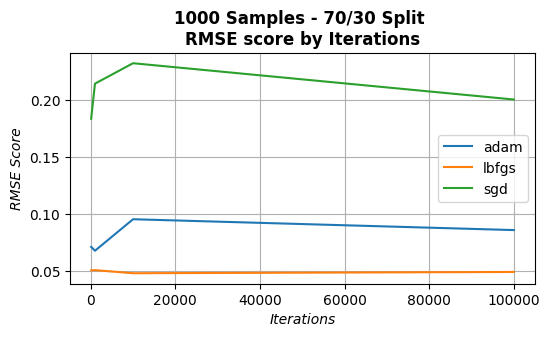

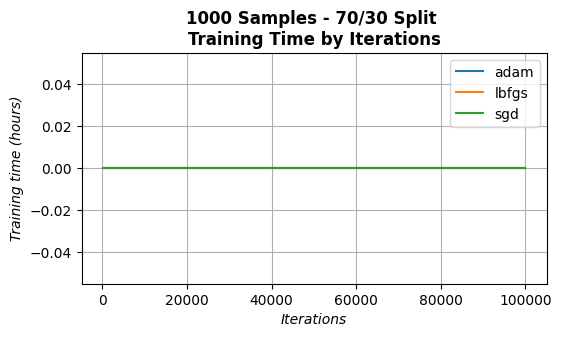

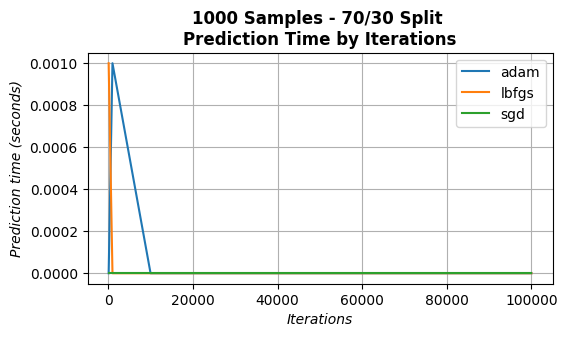

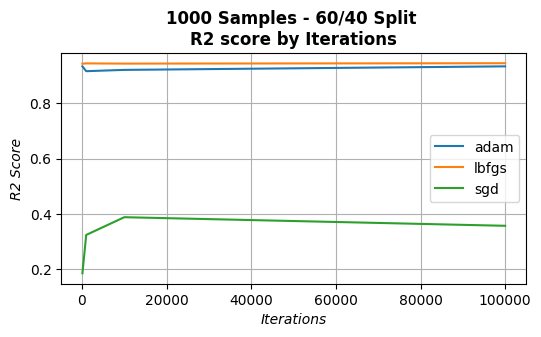

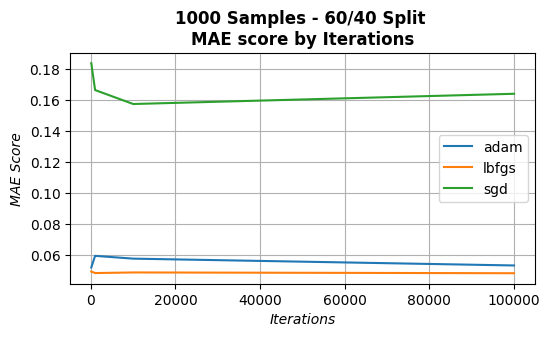

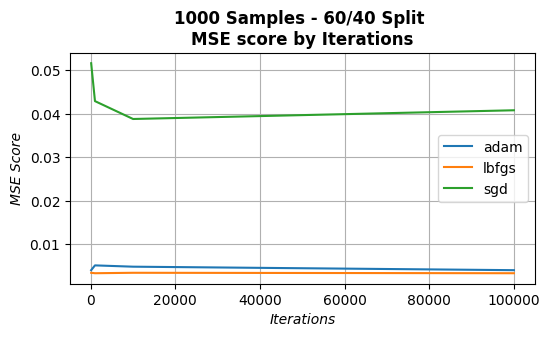

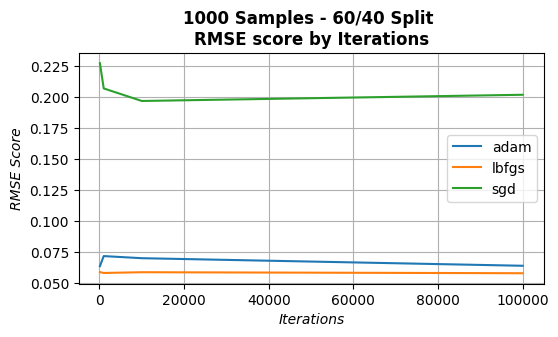

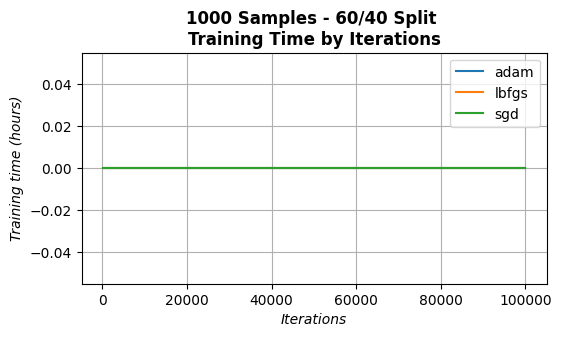

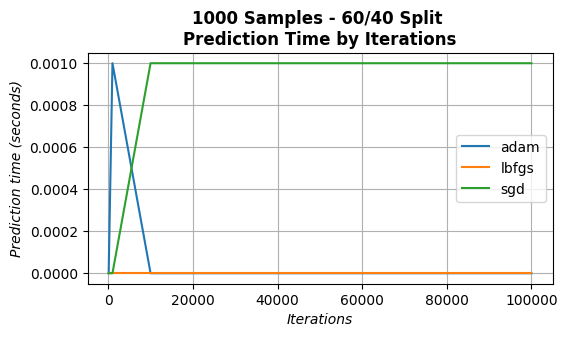

In [6]:
sample_sizes = [100, 500, 1000]
test_sizes = [20, 30, 40]
performance_metrics = ['r2', 'mae', 'mse', 'rmse']
for sample_size in sample_sizes:
    for test_size in test_sizes:
        df_nsamples_by_split = df[(df['n_samples']==sample_size) & (df['test_size'] == test_size)]
        for performance_metric in performance_metrics:
            plot_data(df_nsamples_by_split, 'iterations', performance_metric, f'{sample_size} Samples - {100-test_size}/{test_size} Split \n{performance_metric.upper()} score by Iterations', 'Iterations', f'{performance_metric.upper()} Score')
        plot_data(df_nsamples_by_split, 'iterations', 'training_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nTraining Time by Iterations", "Iterations", "Training time (hours)")
        plot_data(df_nsamples_by_split, 'iterations', 'prediction_time', f"{sample_size} Samples - {100-test_size}/{test_size} Split \nPrediction Time by Iterations", "Iterations", "Prediction time (seconds)")